In [55]:
import numpy as np
import pandas as pd
import cv2
from matplotlib import pyplot as plt
from numpy.linalg import inv
import os

from colormath.color_conversions import convert_color
from colormath.color_objects import LabColor, XYZColor
from colormath.color_diff import delta_e_cie2000

import skimage
from skimage.color import rgb2lab, lab2rgb

from scipy.interpolate import BSpline, make_interp_spline

from scipy.optimize import minimize
from scipy.optimize import dual_annealing
from scipy.optimize import least_squares
from scipy.optimize import basinhopping

from numpy.random import random
from numpy.random import rand

from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf

import time

In [56]:
table1 = np.load('cap1.npy')
table2 = np.load('cap3_2.npy')
table3 = np.load('cap5.npy')

In [57]:
def transfer_by_table(img, table):
    
    # reshape as nx3, and to int
    temp_img = img.reshape(-1, 3).astype(int)

    # transfer to table key
    img_keys = temp_img[:,0] + np.left_shift(temp_img[:,1], 8) + np.left_shift(temp_img[:,2], 16)

    # table mapping
    img_values = table[img_keys]

    # reconstruct to rgb image
    img_r = img_values.astype('uint8')
    img_g = np.right_shift(img_values, 8).astype('uint8')
    img_b = np.right_shift(img_values, 16).astype('uint8')

    img_trans = np.column_stack((img_r, img_g, img_b))

    img_trans = img_trans.reshape(img.shape)
    
    return img_trans

# test transfer

In [58]:
# img = cv2.imread('img_cap3.jpg')
img = cv2.imread('cap1.bmp')

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

t0 = time.time()

nbi = transfer_by_table(img, table1)

print(time.time() - t0)

0.0


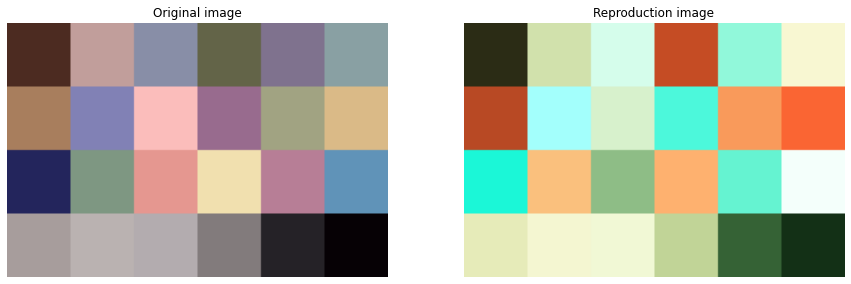

In [59]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(nbi)
plt.title('Reproduction image')
plt.axis('off')

plt.show()

In [62]:
caps1 = np.load('data_cap1.npy')
caps2 = np.load('data_cap3.npy')
caps3 = np.load('data_cap5.npy')

In [63]:
caps1_sim_nbi = transfer_by_table(caps1, table1)
caps2_sim_nbi = transfer_by_table(caps2, table2)
caps3_sim_nbi = transfer_by_table(caps3, table3)

In [64]:
def cal_delta_e_cie2000_lab(lab_src, lab_test):
    
    errs = np.zeros(lab_src.shape[0])
    
    for i in range(lab_src.shape[0]):
        
        color0 = LabColor(lab_l=lab_src[i,0], lab_a=lab_src[i,1], lab_b=lab_src[i,2])
        color1 = LabColor(lab_l=lab_test[i,0], lab_a=lab_test[i,1], lab_b=lab_test[i,2])

        errs[i] = delta_e_cie2000(color0, color1)
        
    return errs

def cal_delta_e_cie2000_rgb(rgb_src, rgb_test):
    
    lab_src = rgb2lab(rgb_src / 255.0)
    lab_test = rgb2lab(rgb_test / 255.0)
    
    errs = np.zeros(lab_src.shape[0])
    
    for i in range(lab_src.shape[0]):
        
        color0 = LabColor(lab_l=lab_src[i,0], lab_a=lab_src[i,1], lab_b=lab_src[i,2])
        color1 = LabColor(lab_l=lab_test[i,0], lab_a=lab_test[i,1], lab_b=lab_test[i,2])

        errs[i] = delta_e_cie2000(color0, color1)
    
    # ignore gray
#     return errs[:-6]

    return errs

def rmse(errs):
    return np.sqrt(((errs) ** 2).mean())

In [65]:
def plot_diff(rgb1, rgb2, dump_file=None):
    
    errs = cal_delta_e_cie2000_rgb(rgb1, rgb2)
    
    plt.figure(figsize=(6, 14))
    plt.axis('off')
    plt.xlim(0, 30)
    plt.ylim(-2, 26)

    plt.annotate('c1.', (8, 25), fontsize = 20)
    plt.annotate('c2.', (16, 25), fontsize = 20)
    plt.annotate('CIEDE2000', (24, 25), fontsize = 20)

    plt.annotate('mean', (16, -1), fontsize = 20)
    plt.annotate('%.2f' %(np.mean(errs)), (26, -1), fontsize = 20)

    plt.annotate('rmse', (16, -2), fontsize = 20)
    plt.annotate('%.2f' %(rmse(errs)), (26, -2), fontsize = 20)
    
    for i in range(24):

        now_c1 = rgb1[i,:]
        now_c2 = rgb2[i,:]

        plt.scatter([10], [24 - i], marker='s', s = 500, color = (now_c1[0]/255, now_c1[1]/255, now_c1[2]/255))
        plt.scatter([18], [24 - i], marker='s', s = 500, color = (now_c2[0]/255, now_c2[1]/255, now_c2[2]/255))

        plt.annotate('%.2f' %(errs[i]), (26, 24 - i - 0.2), fontsize = 20)
        
    if dump_file is not None:
        plt.savefig(dump_file)

    plt.show()

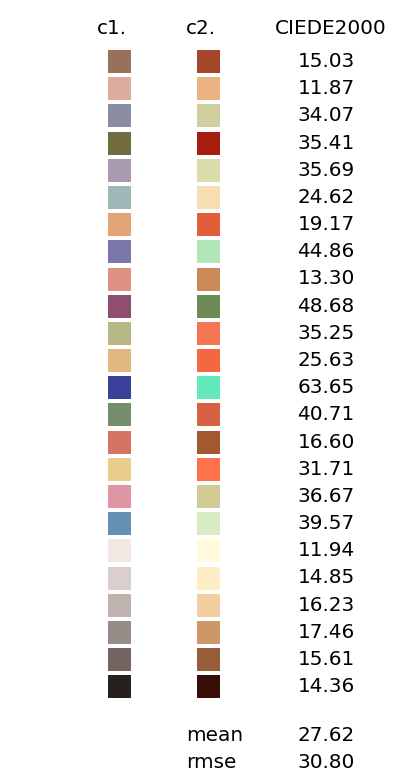

In [69]:
plot_diff(caps2, caps2_sim_nbi)

In [70]:
np.save('data_cap1_nbi.npy', caps1_sim_nbi)
np.save('data_cap3_2_nbi.npy', caps2_sim_nbi)
np.save('data_cap5_nbi.npy', caps3_sim_nbi)